# Create a 2D geometry

Edit the geometry parameters, then run the cells to preview the atomic positions. Set SAVE_GEOMETRY=True to add a geometry CSV. Geometry files are only needed by the 2D model.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


<h1>2D Matter Geometry Creation</h1>

Set `kind`, `lengths`, `matter_width`, `matter_height`, `N_A`, and `N_layer`; the helper generates, saves, and plots the geometry.


In [1]:
SAVE_GEOMETRY = False
SAVE_FIGURES = False  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

import numpy as np

import matplotlib.pyplot as plt

resol = 160
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


from importlib import import_module
create_geometry = import_module("2d_setup.geometry").create_geometry
plot_geometry = import_module("2d_setup.geometry").plot_geometry

<h2>Create geometry</h2>


In [2]:
kind = "slab"  # "slab" or "disk"
lengths = [5, 5]
matter_width = 1
matter_height = 1
N_A = 5
N_layer = 1 # ignored for disk geometries
rotation = np.pi/4

geometry = create_geometry(kind, lengths, matter_width, matter_height, N_A, N_layer, rotation, save=SAVE_GEOMETRY)
geometry["path"]

PosixPath('/Users/romainpiron/Documents/NII_local/light_matter_simu/single_photon_code/2d_setup/database_fiber/geometries/geometry_id6.csv')

<h2>Plot geometry</h2>


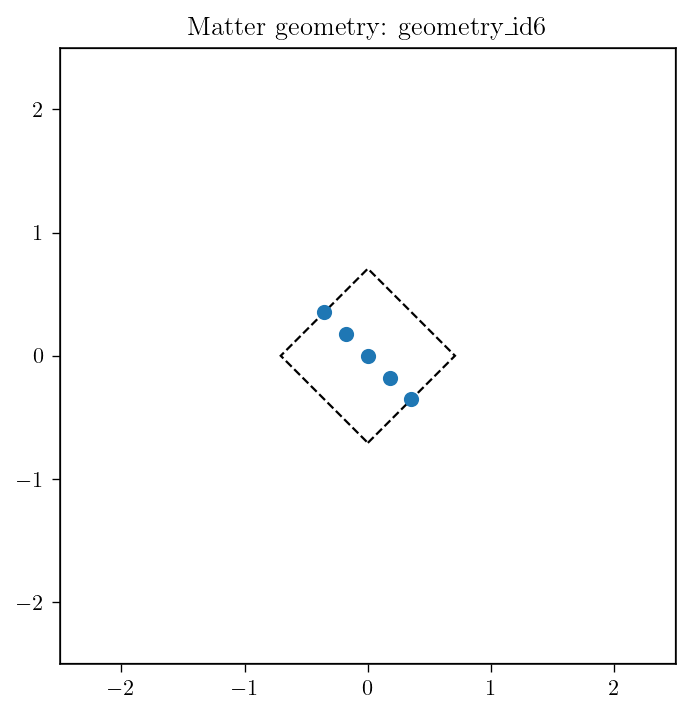

Preview only; set SAVE_GEOMETRY=True to save.


In [3]:
from src.plot_fonts import paper_fonts

fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
plot_geometry(geometry, ax=ax)
ax.set_title(f"Matter geometry: {geometry['label']}")
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 13)
plt.show()

print(f"Saved geometry to: {geometry['path']}" if SAVE_GEOMETRY else "Preview only; set SAVE_GEOMETRY=True to save.")